# 05 - Sizing calculator: putting it all together

Everything from notebooks 01-04 in one place, with sliders:

- **Calculator mode:** you pick the sizes (heat pump, tank, battery, PV)
  and prices, it runs a year of cheapest operation and tells you what it
  costs compared to "business as usual" (gas boiler only, no PV).
- **Sizing mode:** you set the prices and equipment costs, and PyPSA
  picks the sizes that make the total (running cost + yearly share of the
  equipment cost) as small as possible.

Run notebooks 01-03 first (they save the CSVs this one reads).

**The sliders only work when you run the notebook yourself** (Jupyter
Lab / VS Code). On GitHub you only see the default run that's saved
below them.

**Same caveats as notebook 04:** weather is clear-sky and the price is a
made-up duck curve unless you've got real data in `data/`. The equipment
costs are rough guesses, see the cost table.

In [1]:
import sys
sys.path.insert(0, "..")
import logging
import time

import ipywidgets as widgets
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import pypsa
from IPython.display import display

import config

plt.rcParams["figure.dpi"] = 72
logging.getLogger("pypsa").setLevel(logging.WARNING)
logging.getLogger("linopy").setLevel(logging.ERROR)

## Inputs from the other notebooks

In [2]:
demand = pd.read_csv(config.DATA_DIR / "demand_loadcast.csv", index_col=0, parse_dates=True)
pv = pd.read_csv(config.DATA_DIR / "pv_and_weather.csv", index_col=0, parse_dates=True)
cop_map = pd.read_csv(config.DATA_DIR / "cop_map.csv")
hours = demand.index
cop = pd.Series(np.interp(pv.temp_air, cop_map.T_amb, cop_map.COP), index=hours)

# electricity price: real CAISO if notebook 04 downloaded it, otherwise the same made-up duck curve
price_file = config.DATA_DIR / "prices_caiso.csv"
if price_file.exists():
    price = pd.read_csv(price_file, index_col=0, parse_dates=True).iloc[:, 0].reindex(hours).ffill() / 1000
    price_source = "CAISO day-ahead"
else:
    rng = np.random.default_rng(0)
    h = hours.hour.values
    spring = np.isin(hours.month, [3, 4, 5])
    solar_dip = np.clip(np.cos(2 * np.pi * (h - 12.5) / 24), 0, None) ** 2
    evening = np.exp(-((h - 19.5) ** 2) / 4)
    price = pd.Series((50 - 40 * solar_dip * np.where(spring, 1.4, 1.0) + 45 * evening
                       + rng.normal(0, 6, len(h))) / 1000, index=hours)
    price_source = "MADE-UP duck curve"

print("price:", price_source, "| mean COP:", round(cop.mean(), 2))

price: MADE-UP duck curve | mean COP: 2.6


### Speed: every 4th week instead of the whole year

**First try was too slow.** A full year (8,760 hours) took ~10 s in
calculator mode and 25-50 s in sizing mode, which kills the point of
sliders. So by default the model only looks at every 4th week (13 weeks,
still hourly) and counts each of those hours 4 times. Weeks rather than
random hours, so the tank and battery still see real day/night cycles.
Set `FAST = False` for the full year; the experiment log compares the two.

In [3]:
FAST = True
if FAST:
    snaps = hours[((hours.dayofyear - 1) // 7) % 4 == 0]
else:
    snaps = hours
weight = len(hours) / len(snaps)
print(f"modelling {len(snaps)} of {len(hours)} hours, each counted {weight:.2f} times")

modelling 2208 of 8760 hours, each counted 3.97 times


## Equipment costs (rough guesses, change them here)

Installed cost per unit, and how many years it lasts. To compare with
a yearly running cost, each one is turned into a yearly payment like a
loan (the "capital recovery factor").

In [4]:
COSTS = {
    #               $ per unit,  unit,        lifetime (years)
    "heat_pump":   (700,  "kW of heat",   20),
    "tank":        (25,   "kWh of heat",  30),
    "battery":     (400,  "kWh",          12),
    "pv":          (1600, "kWp",          25),
}
DISCOUNT_RATE = 0.07
BOILER_EFF = 0.90
BATTERY_HOURS = 2      # battery power = energy / 2


def yearly_cost(item):
    """$ per unit per year: the installed cost spread over its life as a loan payment."""
    capex, _, years = COSTS[item]
    r = DISCOUNT_RATE
    crf = r * (1 + r) ** years / ((1 + r) ** years - 1)
    return capex * crf


pd.DataFrame([{"item": k, "installed $/unit": v[0], "unit": v[1], "life (yr)": v[2],
               "$/unit/yr": round(yearly_cost(k), 1)} for k, v in COSTS.items()])

,item,installed $/unit,unit,life (yr),$/unit/yr
0,heat_pump,700,kW of heat,20,66.1
1,tank,25,kWh of heat,30,2.0
2,battery,400,kWh,12,50.4
3,pv,1600,kWp,25,137.3


## The model

Same as notebook 04 with two additions:
- **Demand charge.** US industrial tariffs charge for the peak kW you
  pull from the grid. Here the grid connection's size is something the
  optimizer chooses, and each kW costs `demand charge × 12` per year.
  (Real tariffs bill each month's peak separately; using the year's peak
  ×12 is a simplification that overstates it a bit.)
- **Sizing mode.** Anything can be made "extendable", meaning PyPSA picks
  its size, paying its yearly cost per unit.

The gas boiler is assumed to already exist (no equipment cost), and it's
always big enough to cover all the heat on its own, so nothing is ever
infeasible.

In [5]:
def build_network(hp_kw, tank_kwh, battery_kwh, pv_kwp, retail_adder, gas_usd_mmbtu,
                  demand_charge, size_it=False, pv_roof_limit_kwp=2000):
    gas_usd_per_kwh = gas_usd_mmbtu / 293.07   # 1 MMBtu = 293 kWh
    n = pypsa.Network()
    n.set_snapshots(snaps)
    # costs and energy count each hour `weight` times, but storage must still
    # move one real hour per step (my first try weighted those too, and the
    # tank and battery came out far too small - see the experiment log)
    n.snapshot_weightings["objective"] = weight
    n.snapshot_weightings["generators"] = weight
    n.snapshot_weightings["stores"] = 1.0
    n.add("Carrier", ["electricity", "heat", "gas"])
    n.add("Bus", "elec", carrier="electricity")
    n.add("Bus", "heat", carrier="heat")
    n.add("Load", "elec_demand", bus="elec", p_set=demand.elec_kw[snaps])
    n.add("Load", "heat_demand", bus="heat", p_set=demand.heat_kw[snaps])

    n.add("Generator", "grid", bus="elec", carrier="electricity",
          p_nom_extendable=True, capital_cost=demand_charge * 12,
          marginal_cost=(price + retail_adder)[snaps])
    n.add("Generator", "gas_boiler", bus="heat", carrier="gas",
          p_nom=demand.heat_kw.max() * 1.1, marginal_cost=gas_usd_per_kwh / BOILER_EFF)

    # In calculator mode sizes are fixed (but we still add the costs to the
    # objective, so the numbers line up with sizing mode).
    n.add("Generator", "pv", bus="elec", carrier="electricity",
          p_nom=pv_kwp, p_nom_extendable=size_it, p_nom_max=pv_roof_limit_kwp,
          p_max_pu=pv.pv_kw_per_kwp[snaps], capital_cost=yearly_cost("pv"))
    # heat pump size is in kW of heat at the mean COP; the Link counts electricity in
    n.add("Link", "heat_pump", bus0="elec", bus1="heat", carrier="heat",
          p_nom=hp_kw / cop.mean(), p_nom_extendable=size_it, efficiency=cop[snaps],
          capital_cost=yearly_cost("heat_pump") * cop.mean())
    n.add("Store", "tank", bus="heat", carrier="heat", e_cyclic=True, standing_loss=0.002,
          e_nom=tank_kwh, e_nom_extendable=size_it, capital_cost=yearly_cost("tank"))
    n.add("StorageUnit", "battery", bus="elec", carrier="electricity",
          p_nom=battery_kwh / BATTERY_HOURS, p_nom_extendable=size_it, max_hours=BATTERY_HOURS,
          cyclic_state_of_charge=True, efficiency_store=0.95, efficiency_dispatch=0.95,
          capital_cost=yearly_cost("battery") * BATTERY_HOURS)
    return n


def solve(n):
    status, condition = n.optimize(solver_name="highs", solver_options={"output_flag": False},
                                   include_objective_constant=False, progress=False)
    assert condition == "optimal", condition
    return n


def summarise(n, retail_adder, gas_usd_mmbtu, demand_charge):
    """Turn a solved network into sizes and a yearly cost breakdown."""
    sizes = {
        "heat_pump_kW_heat": n.links.p_nom_opt["heat_pump"] * cop.mean(),
        "tank_kWh": n.stores.e_nom_opt["tank"],
        "battery_kWh": n.storage_units.p_nom_opt["battery"] * BATTERY_HOURS,
        "pv_kWp": n.generators.p_nom_opt["pv"],
    }
    sizes = {k: max(0.0, v) for k, v in sizes.items()}   # the solver sometimes says -0.0
    # every modelled hour stands for `weight` real hours
    grid = n.generators_t.p["grid"]
    boiler = n.generators_t.p["gas_boiler"] * weight
    hp_heat = n.links_t.p1["heat_pump"].abs() * weight
    costs = {
        "electricity energy": (grid * (price + retail_adder)[snaps]).sum() * weight,
        "demand charge": grid.max() * demand_charge * 12,
        "gas": boiler.sum() * gas_usd_mmbtu / 293.07 / BOILER_EFF,
        "equipment (yearly)": (sizes["heat_pump_kW_heat"] * yearly_cost("heat_pump")
                               + sizes["tank_kWh"] * yearly_cost("tank")
                               + sizes["battery_kWh"] * yearly_cost("battery")
                               + sizes["pv_kWp"] * yearly_cost("pv")),
    }
    other = {
        "peak_grid_kW": grid.max(),
        "heat_pump_share_of_heat": hp_heat.sum() / (hp_heat.sum() + boiler.sum()),
        "gas_MWh": boiler.sum() / BOILER_EFF / 1000,
        "grid_MWh": grid.sum() * weight / 1000,
    }
    return sizes, costs, other


def business_as_usual(retail_adder, gas_usd_mmbtu, demand_charge):
    """Gas boiler only, no PV, no storage: what the plant pays today."""
    n = solve(build_network(0, 0, 0, 0, retail_adder, gas_usd_mmbtu, demand_charge))
    return summarise(n, retail_adder, gas_usd_mmbtu, demand_charge)

## Calculator mode

Pick the sizes and prices, then press **Run**. Each run solves a full
year twice (your design and business as usual), a few seconds each.

In [6]:
def calculator(hp_kw=1500, tank_kwh=4000, battery_kwh=0, pv_kwp=1000,
               retail_adder=0.0, gas_usd_mmbtu=8.0, demand_charge=0.0):
    t0 = time.time()
    n = solve(build_network(hp_kw, tank_kwh, battery_kwh, pv_kwp, retail_adder, gas_usd_mmbtu, demand_charge))
    sizes, costs, other = summarise(n, retail_adder, gas_usd_mmbtu, demand_charge)
    _, bau_costs, bau_other = business_as_usual(retail_adder, gas_usd_mmbtu, demand_charge)

    table = pd.DataFrame({"business as usual": bau_costs, "your design": costs})
    table.loc["TOTAL per year"] = table.sum()
    saving = table.loc["TOTAL per year", "business as usual"] - table.loc["TOTAL per year", "your design"]
    capex = (hp_kw * COSTS["heat_pump"][0] + tank_kwh * COSTS["tank"][0]
             + battery_kwh * COSTS["battery"][0] + pv_kwp * COSTS["pv"][0])
    running_saving = saving + costs["equipment (yearly)"]

    print(f"solved in {time.time() - t0:.1f} s   (price: {price_source})\n")
    display(table.round(0).astype(int).style.format("${:,}"))
    print(f"\nupfront equipment cost:      ${capex:,.0f}")
    print(f"running-cost saving per year: ${running_saving:,.0f}"
          + (f"  -> simple payback {capex / running_saving:.1f} years" if running_saving > 0 else "  -> never pays back"))
    print(f"total saving per year incl. equipment: ${saving:,.0f}  ({'worth it' if saving > 0 else 'NOT worth it'} at these costs)")
    print(f"heat pump share of heat: {other['heat_pump_share_of_heat']:.0%}   "
          f"peak grid: {other['peak_grid_kW']:,.0f} kW (was {bau_other['peak_grid_kW']:,.0f})   "
          f"gas: {other['gas_MWh']:,.0f} MWh (was {bau_other['gas_MWh']:,.0f})")

    # 4 days from the first modelled week starting after mid-April
    start = snaps[snaps >= f"{config.YEAR}-04-15"][0]
    w = slice(start, start + pd.offsets.Day(4))
    fig, ax = plt.subplots(1, 3, figsize=(15, 3.5), gridspec_kw={"width_ratios": [1, 2.2, 2.2]})
    table.drop("TOTAL per year").T.plot.bar(stacked=True, ax=ax[0], rot=0, legend=False)
    ax[0].set_title("yearly cost ($)"); ax[0].legend(fontsize=7)
    heat = pd.DataFrame({"heat pump": n.links_t.p1["heat_pump"].abs(),
                         "gas boiler": n.generators_t.p["gas_boiler"]})
    heat.loc[w].plot.area(ax=ax[1], linewidth=0, alpha=0.8)
    demand.heat_kw[snaps].loc[w].plot(ax=ax[1], color="k", ls="--", label="heat demand")
    ax[1].set_title("heat supply, 4 days in late April (kW)"); ax[1].legend(fontsize=7)
    elec = pd.DataFrame({"grid": n.generators_t.p["grid"], "pv": n.generators_t.p["pv"]})
    elec.loc[w].plot(ax=ax[2])
    if battery_kwh > 0:
        n.storage_units_t.p["battery"].loc[w].plot(ax=ax[2], label="battery (+ discharge)")
    ax[2].set_title("electricity, same week (kW)"); ax[2].legend(fontsize=7)
    plt.tight_layout(); plt.show()

Default run (this is what GitHub shows):

solved in 4.2 s   (price: MADE-UP duck curve)



,business as usual,your design
electricity energy,"$89,295","$143,501"
demand charge,$0,$0
gas,"$209,842","$1,822"
equipment (yearly),$0,"$244,468"
TOTAL per year,"$299,137","$389,790"



upfront equipment cost:      $2,750,000
running-cost saving per year: $153,814  -> simple payback 17.9 years
total saving per year incl. equipment: $-90,654  (NOT worth it at these costs)
heat pump share of heat: 99%   peak grid: 1,147 kW (was 569)   gas: 67 MWh (was 7,687)


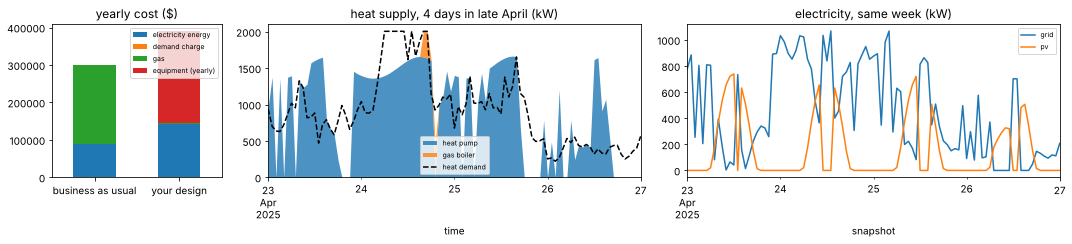

In [7]:
calculator()

In [8]:
slider = dict(continuous_update=False, style={"description_width": "170px"},
              layout=widgets.Layout(width="480px"))
widgets.interact_manual(
    calculator,
    hp_kw=widgets.IntSlider(value=1500, min=0, max=3000, step=250, description="heat pump (kW heat)", **slider),
    tank_kwh=widgets.IntSlider(value=4000, min=0, max=20000, step=1000, description="hot water tank (kWh)", **slider),
    battery_kwh=widgets.IntSlider(value=0, min=0, max=4000, step=500, description="battery (kWh)", **slider),
    pv_kwp=widgets.IntSlider(value=1000, min=0, max=2000, step=250, description="PV (kWp)", **slider),
    retail_adder=widgets.FloatSlider(value=0.0, min=0, max=0.15, step=0.01, description="grid charges ($/kWh)", **slider),
    gas_usd_mmbtu=widgets.FloatSlider(value=8.0, min=2, max=20, step=0.5, description="gas price ($/MMBtu)", **slider),
    demand_charge=widgets.FloatSlider(value=0.0, min=0, max=40, step=2.5, description="demand charge ($/kW-month)", **slider),
);

interactive(children=(IntSlider(value=1500, continuous_update=False, description='heat pump (kW heat)', layout…

## Sizing mode: let PyPSA choose

Same model, but every size is a decision. PyPSA trades each kW or kWh's
yearly equipment cost against what it saves in running cost. PV is
capped by the roof.

In [9]:
def size_it(retail_adder=0.0, gas_usd_mmbtu=8.0, demand_charge=0.0, pv_roof_limit_kwp=2000,
            battery_cost=400):
    COSTS["battery"] = (battery_cost, "kWh", COSTS["battery"][2])
    t0 = time.time()
    n = solve(build_network(0, 0, 0, 0, retail_adder, gas_usd_mmbtu, demand_charge,
                            size_it=True, pv_roof_limit_kwp=pv_roof_limit_kwp))
    sizes, costs, other = summarise(n, retail_adder, gas_usd_mmbtu, demand_charge)
    _, bau_costs, _ = business_as_usual(retail_adder, gas_usd_mmbtu, demand_charge)
    print(f"solved in {time.time() - t0:.1f} s\n")
    print("PyPSA's choice:")
    for k, v in sizes.items():
        print(f"  {k:20s} {v:10,.0f}")
    print(f"\nyearly total ${sum(costs.values()):,.0f} vs business as usual ${sum(bau_costs.values()):,.0f}"
          f"  (saves ${sum(bau_costs.values()) - sum(costs.values()):,.0f}/yr)")
    print(f"heat pump share of heat {other['heat_pump_share_of_heat']:.0%}, peak grid {other['peak_grid_kW']:,.0f} kW")
    COSTS["battery"] = (400, "kWh", COSTS["battery"][2])
    return sizes

In [10]:
size_it();

solved in 6.3 s

PyPSA's choice:
  heat_pump_kW_heat           930
  tank_kWh                  2,998
  battery_kWh                   0
  pv_kWp                        0

yearly total $271,541 vs business as usual $299,137  (saves $27,595/yr)
heat pump share of heat 87%, peak grid 927 kW


In [11]:
widgets.interact_manual(
    size_it,
    retail_adder=widgets.FloatSlider(value=0.0, min=0, max=0.15, step=0.01, description="grid charges ($/kWh)", **slider),
    gas_usd_mmbtu=widgets.FloatSlider(value=8.0, min=2, max=20, step=0.5, description="gas price ($/MMBtu)", **slider),
    demand_charge=widgets.FloatSlider(value=0.0, min=0, max=40, step=2.5, description="demand charge ($/kW-month)", **slider),
    pv_roof_limit_kwp=widgets.IntSlider(value=2000, min=0, max=5000, step=250, description="roof limit for PV (kWp)", **slider),
    battery_cost=widgets.IntSlider(value=400, min=100, max=800, step=50, description="battery cost ($/kWh)", **slider),
);

interactive(children=(FloatSlider(value=0.0, continuous_update=False, description='grid charges ($/kWh)', layo…

## Does the "every 4th week" shortcut change the answer?
Same sizing run on the full year, to check.

In [12]:
fast_snaps, fast_weight = snaps, weight
snaps, weight = hours, 1.0
t0 = time.time()
full_year = size_it()
print(f"\nfull year took {time.time() - t0:.0f} s")
snaps, weight = fast_snaps, fast_weight
t0 = time.time()
sampled = size_it()
print(f"\nevery 4th week took {time.time() - t0:.0f} s")
pd.DataFrame({"full year": full_year, "every 4th week": sampled}).round(0)

solved in 43.2 s

PyPSA's choice:
  heat_pump_kW_heat           928
  tank_kWh                  2,911
  battery_kWh                   0
  pv_kWp                        0

yearly total $275,876 vs business as usual $303,678  (saves $27,802/yr)
heat pump share of heat 86%, peak grid 927 kW

full year took 43 s


solved in 6.3 s

PyPSA's choice:
  heat_pump_kW_heat           930
  tank_kWh                  2,998
  battery_kWh                   0
  pv_kWp                        0

yearly total $271,541 vs business as usual $299,137  (saves $27,595/yr)
heat pump share of heat 87%, peak grid 927 kW

every 4th week took 6 s


,full year,every 4th week
heat_pump_kW_heat,928.0,930.0
tank_kWh,2911.0,2998.0
battery_kWh,0.0,0.0
pv_kWp,0.0,0.0


## A few runs I tried

Sizing mode across a few price situations, to see what changes the answer.

In [13]:
cases = {
    "wholesale only": dict(),
    "+ $0.06/kWh grid charges": dict(retail_adder=0.06),
    "+ $0.06/kWh + $20/kW-month demand charge": dict(retail_adder=0.06, demand_charge=20),
    "cheap gas ($4)": dict(gas_usd_mmbtu=4),
    "expensive gas ($14)": dict(gas_usd_mmbtu=14),
    "cheap batteries ($150/kWh)": dict(battery_cost=150),
}
rows = {}
for name, kw in cases.items():
    print(f"--- {name}")
    rows[name] = size_it(**kw)
    print()
pd.DataFrame(rows).T.round(0)

--- wholesale only


solved in 6.2 s

PyPSA's choice:
  heat_pump_kW_heat           930
  tank_kWh                  2,998
  battery_kWh                   0
  pv_kWp                        0

yearly total $271,541 vs business as usual $299,137  (saves $27,595/yr)
heat pump share of heat 87%, peak grid 927 kW

--- + $0.06/kWh grid charges


solved in 5.8 s

PyPSA's choice:
  heat_pump_kW_heat             0
  tank_kWh                      0
  battery_kWh                   0
  pv_kWp                       94

yearly total $417,788 vs business as usual $417,853  (saves $65/yr)
heat pump share of heat 0%, peak grid 569 kW

--- + $0.06/kWh + $20/kW-month demand charge


solved in 6.2 s

PyPSA's choice:
  heat_pump_kW_heat             0
  tank_kWh                      0
  battery_kWh                 728
  pv_kWp                      297

yearly total $533,580 vs business as usual $554,498  (saves $20,919/yr)
heat pump share of heat 0%, peak grid 403 kW

--- cheap gas ($4)


solved in 4.8 s

PyPSA's choice:
  heat_pump_kW_heat             0
  tank_kWh                      0
  battery_kWh                   0
  pv_kWp                        0

yearly total $194,216 vs business as usual $194,216  (saves $0/yr)
heat pump share of heat 0%, peak grid 569 kW

--- expensive gas ($14)


solved in 6.3 s

PyPSA's choice:
  heat_pump_kW_heat         1,183
  tank_kWh                  4,997
  battery_kWh                   0
  pv_kWp                        0

yearly total $276,867 vs business as usual $456,518  (saves $179,651/yr)
heat pump share of heat 99%, peak grid 1,025 kW

--- cheap batteries ($150/kWh)


solved in 6.8 s

PyPSA's choice:
  heat_pump_kW_heat           846
  tank_kWh                  2,134
  battery_kWh               2,420
  pv_kWp                        0

yearly total $257,658 vs business as usual $299,137  (saves $41,479/yr)
heat pump share of heat 88%, peak grid 2,105 kW



,heat_pump_kW_heat,tank_kWh,battery_kWh,pv_kWp
wholesale only,930.0,2998.0,0.0,0.0
+ $0.06/kWh grid charges,0.0,0.0,0.0,94.0
+ $0.06/kWh + $20/kW-month demand charge,0.0,0.0,728.0,297.0
cheap gas ($4),0.0,0.0,0.0,0.0
expensive gas ($14),1183.0,4997.0,0.0,0.0
cheap batteries ($150/kWh),846.0,2134.0,2420.0,0.0


## Notes to self

- **The default design doesn't pay off** (payback ~18 years). Most of the
  $2.75M upfront is the 1 MWp of PV at $1,600/kWp. Each kWp costs ~$137
  a year (spread over 25 years at 7%) but makes ~1,750 kWh that are worth
  only ~$70 at wholesale prices, which are lowest exactly when the sun is
  out. PyPSA never picks much PV unless there's a demand charge. With a real retail tariff (much higher than wholesale) that
  would change.
- **Sizing mode at wholesale prices** picks a ~930 kW heat pump and a
  ~3 MWh tank, with the boiler kept for the cold-morning peaks. Not the
  1.5 MW I settled on in notebook 04, because now the heat pump has to pay
  for itself.
- **Gas price flips everything.** At $4/MMBtu nothing is worth building.
  At $14 the heat pump (1.2 MW) and a 5 MWh tank save ~$180k/yr.
- **Grid charges kill the heat pump**: at +$0.06/kWh it picks no heat
  pump at all. The spark spread is what matters, not the COP alone.
- **A demand charge is what makes a battery worth it** (and some PV):
  ~730 kWh battery and ~300 kWp PV at $20/kW-month, used to shave the peak.
  Cheap batteries ($150/kWh) get bought for price arbitrage instead, and
  then peak grid import goes UP to 2.1 MW, which is why the demand charge
  matters.
- Remember these use the made-up duck curve. Re-run with real CAISO
  prices and a real tariff before believing any of the numbers.